In [1]:
# FINAURA
# Delhi Diesel Price Data Preprocessing
# Dataset 07

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
input_path = "../data/raw/delhi_diesel_raw.csv"
output_path = "../data/processed/delhi_diesel_processed.csv"

In [4]:
df = pd.read_csv(input_path)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (3372, 3)


In [5]:
df.head()

,Date,City,Diesel_Price
0,2017-06-16,Delhi,54.49
1,2017-06-17,Delhi,54.32
2,2017-06-18,Delhi,54.14
3,2017-06-19,Delhi,54.01
4,2017-06-20,Delhi,53.96


In [6]:
df.tail()

,Date,City,Diesel_Price
3367,2026-09-04,Delhi,95.2
3368,2026-09-05,Delhi,95.2
3369,2026-09-06,Delhi,95.2
3370,2026-09-07,Delhi,95.2
3371,2026-09-08,Delhi,95.2


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3372 entries, 0 to 3371
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          3372 non-null   object 
 1   City          3372 non-null   object 
 2   Diesel_Price  3372 non-null   float64
dtypes: float64(1), object(2)
memory usage: 79.2+ KB


In [8]:
df.describe(include="all")

,Date,City,Diesel_Price
count,3372,3372,3372.000000
unique,3372,1,NaN
top,2017-06-16,Delhi,NaN
freq,1,3372,NaN
mean,NaN,NaN,79.926438
std,NaN,NaN,11.675900
min,NaN,NaN,53.330000
25%,NaN,NaN,67.607500
50%,NaN,NaN,87.620000
75%,NaN,NaN,89.620000


In [9]:
print(df.columns.tolist())

['Date', 'City', 'Diesel_Price']


In [10]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['date', 'city', 'diesel_price']


In [11]:
df = df.rename(columns={
    "date": "date",
    "city": "city",
    "diesel_price": "diesel_price"
})

df.head()

,date,city,diesel_price
0,2017-06-16,Delhi,54.49
1,2017-06-17,Delhi,54.32
2,2017-06-18,Delhi,54.14
3,2017-06-19,Delhi,54.01
4,2017-06-20,Delhi,53.96


In [12]:
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["diesel_price"] = pd.to_numeric(df["diesel_price"], errors="coerce")

print(df.dtypes)

date            datetime64[ns]
city                    object
diesel_price           float64
dtype: object


In [13]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
date            0
city            0
diesel_price    0
dtype: int64


In [14]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

date            0.0
city            0.0
diesel_price    0.0
dtype: float64


In [15]:
print("Cities available:")
print(df["city"].unique())

Cities available:
['Delhi']


In [16]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [17]:
print(
    "Duplicate date-city records:",
    df.duplicated(subset=["date", "city"]).sum()
)

Duplicate date-city records: 0


In [18]:
df = df.drop_duplicates(subset=["date", "city"])

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (3372, 3)


In [19]:
print("Invalid dates:", df["date"].isna().sum())

Invalid dates: 0


In [20]:
df = df.dropna(subset=["date"])

print("Shape:", df.shape)

Shape: (3372, 3)


In [21]:
df = df.sort_values("date").reset_index(drop=True)

df.head()

,date,city,diesel_price
0,2017-06-16,Delhi,54.49
1,2017-06-17,Delhi,54.32
2,2017-06-18,Delhi,54.14
3,2017-06-19,Delhi,54.01
4,2017-06-20,Delhi,53.96


In [22]:
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

Start Date: 2017-06-16 00:00:00
End Date: 2026-09-08 00:00:00


In [23]:
print("Missing diesel prices:", df["diesel_price"].isna().sum())

Missing diesel prices: 0


In [24]:
print("Non-positive prices:", (df["diesel_price"] <= 0).sum())

Non-positive prices: 0


In [25]:
df = df[df["diesel_price"] > 0].copy()

print("Shape after price validation:", df.shape)


Shape after price validation: (3372, 3)


In [26]:
df["previous_diesel_price"] = df["diesel_price"].shift(1)

df.head()

,date,city,diesel_price,previous_diesel_price
0,2017-06-16,Delhi,54.49,NaN
1,2017-06-17,Delhi,54.32,54.49
2,2017-06-18,Delhi,54.14,54.32
3,2017-06-19,Delhi,54.01,54.14
4,2017-06-20,Delhi,53.96,54.01


In [27]:
df["diesel_price_change"] = (
    df["diesel_price"] - df["previous_diesel_price"]
)

df.head()

,date,city,diesel_price,previous_diesel_price,diesel_price_change
0,2017-06-16,Delhi,54.49,NaN,NaN
1,2017-06-17,Delhi,54.32,54.49,-0.17
2,2017-06-18,Delhi,54.14,54.32,-0.18
3,2017-06-19,Delhi,54.01,54.14,-0.13
4,2017-06-20,Delhi,53.96,54.01,-0.05


In [28]:
df["diesel_return"] = df["diesel_price"].pct_change()

df.head()

,date,city,diesel_price,previous_diesel_price,diesel_price_change,diesel_return
0,2017-06-16,Delhi,54.49,NaN,NaN,NaN
1,2017-06-17,Delhi,54.32,54.49,-0.17,-0.003120
2,2017-06-18,Delhi,54.14,54.32,-0.18,-0.003314
3,2017-06-19,Delhi,54.01,54.14,-0.13,-0.002401
4,2017-06-20,Delhi,53.96,54.01,-0.05,-0.000926


In [29]:
df["log_return"] = np.log(
    df["diesel_price"] / df["previous_diesel_price"]
)

df.head()

,date,city,diesel_price,previous_diesel_price,diesel_price_change,diesel_return,log_return
0,2017-06-16,Delhi,54.49,NaN,NaN,NaN,NaN
1,2017-06-17,Delhi,54.32,54.49,-0.17,-0.003120,-0.003125
2,2017-06-18,Delhi,54.14,54.32,-0.18,-0.003314,-0.003319
3,2017-06-19,Delhi,54.01,54.14,-0.13,-0.002401,-0.002404
4,2017-06-20,Delhi,53.96,54.01,-0.05,-0.000926,-0.000926


In [30]:
df["diesel_ma_7"] = df["diesel_price"].rolling(7).mean()

df["diesel_ma_30"] = df["diesel_price"].rolling(30).mean()

df[[
    "date",
    "diesel_price",
    "diesel_ma_7",
    "diesel_ma_30"
]].tail()

,date,diesel_price,diesel_ma_7,diesel_ma_30
3367,2026-09-04,95.2,95.2,95.2
3368,2026-09-05,95.2,95.2,95.2
3369,2026-09-06,95.2,95.2,95.2
3370,2026-09-07,95.2,95.2,95.2
3371,2026-09-08,95.2,95.2,95.2


In [31]:
df["volatility_7d"] = df["diesel_return"].rolling(7).std()

df["volatility_30d"] = df["diesel_return"].rolling(30).std()

df[[
    "date",
    "volatility_7d",
    "volatility_30d"
]].tail()

,date,volatility_7d,volatility_30d
3367,2026-09-04,0.0,0.0
3368,2026-09-05,0.0,0.0
3369,2026-09-06,0.0,0.0
3370,2026-09-07,0.0,0.0
3371,2026-09-08,0.0,0.0


In [32]:
df["momentum_7d"] = (
    df["diesel_price"] / df["diesel_price"].shift(7) - 1
)

df["momentum_30d"] = (
    df["diesel_price"] / df["diesel_price"].shift(30) - 1
)

df[[
    "date",
    "momentum_7d",
    "momentum_30d"
]].tail()

,date,momentum_7d,momentum_30d
3367,2026-09-04,0.0,0.0
3368,2026-09-05,0.0,0.0
3369,2026-09-06,0.0,0.0
3370,2026-09-07,0.0,0.0
3371,2026-09-08,0.0,0.0


In [33]:
df["price_vs_ma_7"] = (
    df["diesel_price"] / df["diesel_ma_7"] - 1
)

df["price_vs_ma_30"] = (
    df["diesel_price"] / df["diesel_ma_30"] - 1
)

df.tail()

,date,city,diesel_price,previous_diesel_price,diesel_price_change,diesel_return,log_return,diesel_ma_7,diesel_ma_30,volatility_7d,volatility_30d,momentum_7d,momentum_30d,price_vs_ma_7,price_vs_ma_30
3367,2026-09-04,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0
3368,2026-09-05,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0
3369,2026-09-06,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0
3370,2026-09-07,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0
3371,2026-09-08,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0


In [34]:
df["target_next_day_diesel_price"] = (
    df["diesel_price"].shift(-1)
)

df.tail()

,date,city,diesel_price,previous_diesel_price,diesel_price_change,diesel_return,log_return,diesel_ma_7,diesel_ma_30,volatility_7d,volatility_30d,momentum_7d,momentum_30d,price_vs_ma_7,price_vs_ma_30,target_next_day_diesel_price
3367,2026-09-04,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0,95.2
3368,2026-09-05,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0,95.2
3369,2026-09-06,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0,95.2
3370,2026-09-07,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0,95.2
3371,2026-09-08,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0,NaN


In [35]:
df["target_next_day_change"] = (
    df["target_next_day_diesel_price"] - df["diesel_price"]
)

df.tail()

,date,city,diesel_price,previous_diesel_price,diesel_price_change,diesel_return,log_return,diesel_ma_7,diesel_ma_30,volatility_7d,volatility_30d,momentum_7d,momentum_30d,price_vs_ma_7,price_vs_ma_30,target_next_day_diesel_price,target_next_day_change
3367,2026-09-04,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0,95.2,0.0
3368,2026-09-05,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0,95.2,0.0
3369,2026-09-06,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0,95.2,0.0
3370,2026-09-07,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0,95.2,0.0
3371,2026-09-08,Delhi,95.2,95.2,0.0,0.0,0.0,95.2,95.2,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN


In [36]:
feature_columns = [
    "previous_diesel_price",
    "diesel_price_change",
    "diesel_return",
    "log_return",
    "diesel_ma_7",
    "diesel_ma_30",
    "volatility_7d",
    "volatility_30d",
    "momentum_7d",
    "momentum_30d",
    "price_vs_ma_7",
    "price_vs_ma_30"
]

target_columns = [
    "target_next_day_diesel_price",
    "target_next_day_change"
]

print("Feature columns:")
print(feature_columns)

print("\nTarget columns:")
print(target_columns)

Feature columns:
['previous_diesel_price', 'diesel_price_change', 'diesel_return', 'log_return', 'diesel_ma_7', 'diesel_ma_30', 'volatility_7d', 'volatility_30d', 'momentum_7d', 'momentum_30d', 'price_vs_ma_7', 'price_vs_ma_30']

Target columns:
['target_next_day_diesel_price', 'target_next_day_change']


In [37]:
print("Missing target values:")

print(
    df[target_columns].isnull().sum()
)

Missing target values:
target_next_day_diesel_price    1
target_next_day_change          1
dtype: int64


In [38]:
df = df.dropna().reset_index(drop=True)

print("Final shape:", df.shape)

Final shape: (3341, 17)


In [39]:
print("Final Dataset Information")
print("-------------------------")

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

Final Dataset Information
-------------------------
Rows: 3341
Columns: 17

Missing values:
0

Duplicate rows:
0

Date range:
2017-07-16 00:00:00 to 2026-09-07 00:00:00


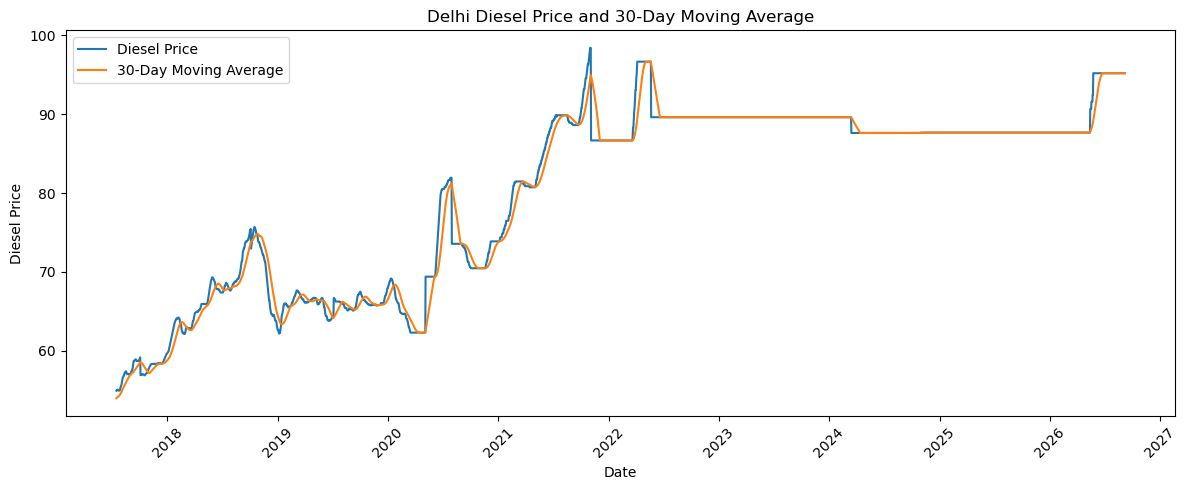

In [40]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["date"],
    df["diesel_price"],
    label="Diesel Price"
)

plt.plot(
    df["date"],
    df["diesel_ma_30"],
    label="30-Day Moving Average"
)

plt.xlabel("Date")
plt.ylabel("Diesel Price")
plt.title("Delhi Diesel Price and 30-Day Moving Average")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

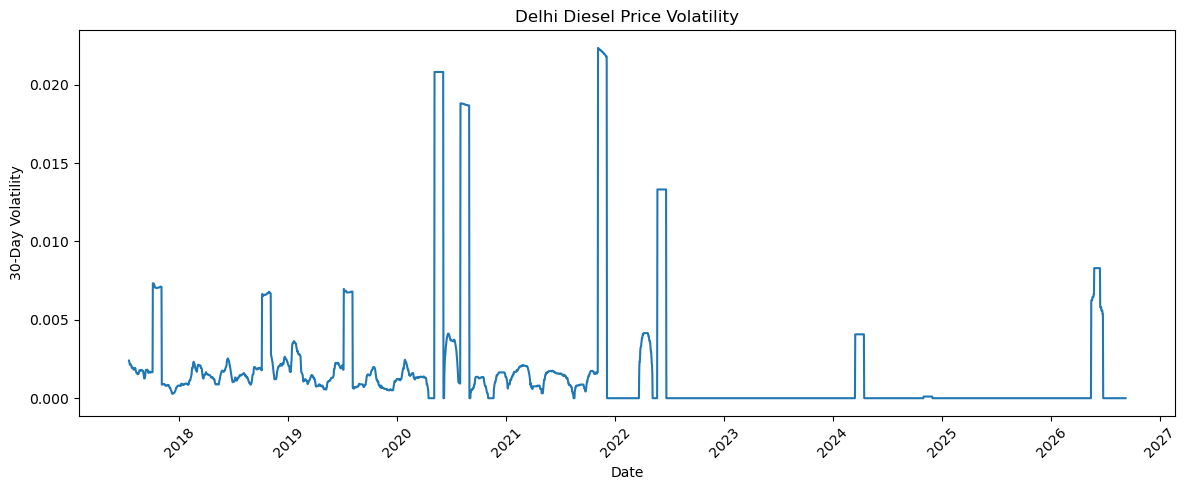

In [41]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["date"],
    df["volatility_30d"]
)

plt.xlabel("Date")
plt.ylabel("30-Day Volatility")
plt.title("Delhi Diesel Price Volatility")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [42]:
df.to_csv(output_path, index=False)

print("Processed Delhi Diesel dataset saved successfully!")
print(output_path)

Processed Delhi Diesel dataset saved successfully!
../data/processed/delhi_diesel_processed.csv
